In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
results = [
    {
        "Model": "Logistic Regression",
        "Version": "Original",
        "Accuracy": 0.8041,
        "Precision": 0.6467,
        "Recall": 0.5775,
        "F1-Score": 0.6102
    },
    {
        "Model": "Decision Tree",
        "Version": "Original",
        "Accuracy": 0.7268,
        "Precision": 0.4861,
        "Recall": 0.5134,
        "F1-Score": 0.4993
    }
]

comparison = pd.DataFrame(results)

comparison

,Model,Version,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,Original,0.8041,0.6467,0.5775,0.6102
1,Decision Tree,Original,0.7268,0.4861,0.5134,0.4993


In [3]:
display_table = comparison.copy()

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

for metric in metrics:
    display_table[metric] = (
        display_table[metric] * 100
    ).round(2).astype(str) + "%"

display_table

,Model,Version,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,Original,80.41%,64.67%,57.75%,61.02%
1,Decision Tree,Original,72.68%,48.61%,51.34%,49.93%


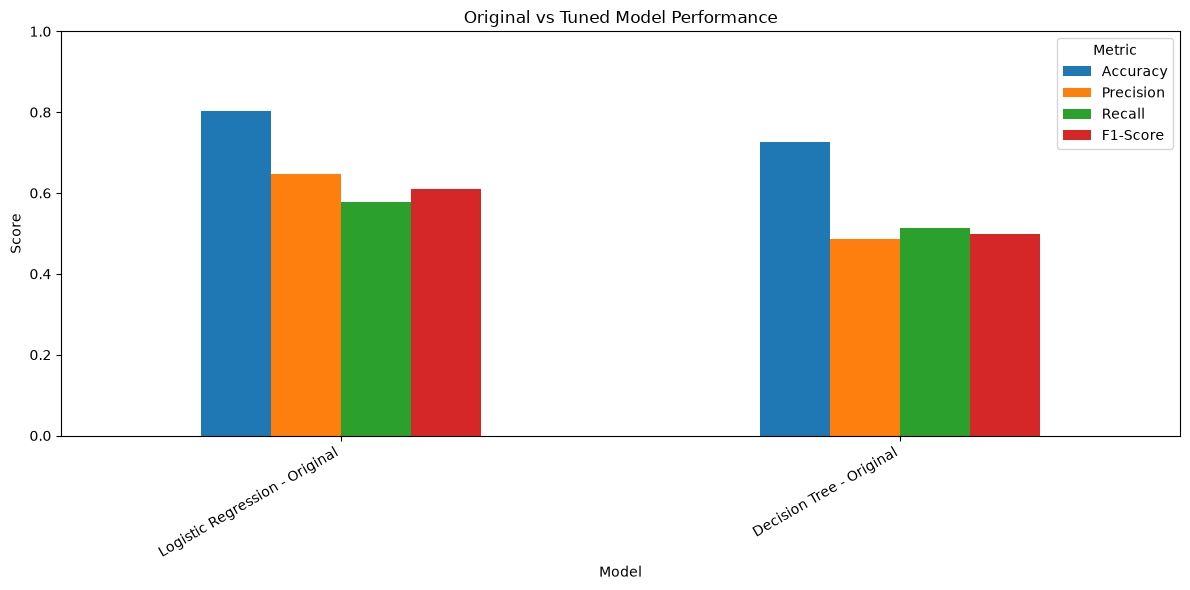

In [4]:
plot_data = comparison.copy()

plot_data["Model Version"] = (
    plot_data["Model"] + " - " + plot_data["Version"]
)

plot_data = plot_data.set_index("Model Version")

plot_data[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Original vs Tuned Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

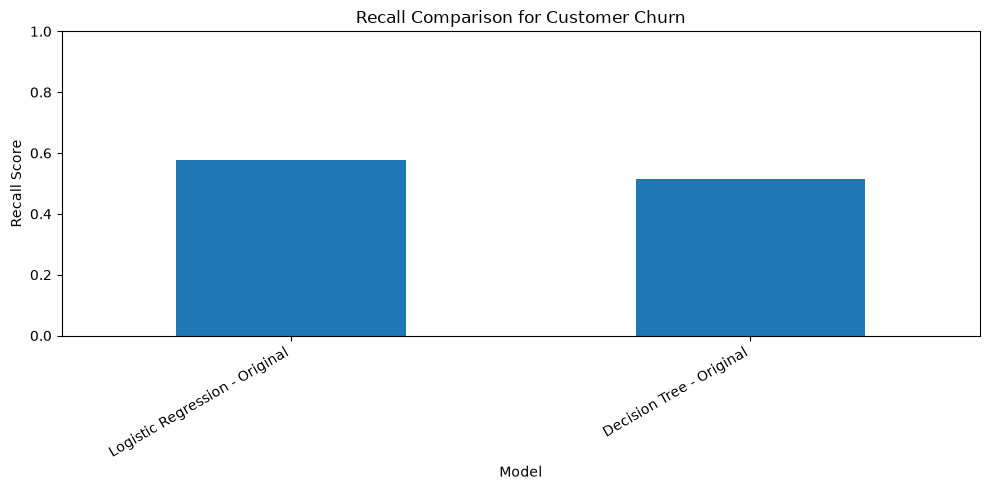

In [5]:
recall_data = comparison.copy()

recall_data["Model Version"] = (
    recall_data["Model"] + " - " + recall_data["Version"]
)

recall_data.plot(
    x="Model Version",
    y="Recall",
    kind="bar",
    figsize=(10, 5),
    legend=False
)

plt.title("Recall Comparison for Customer Churn")
plt.ylabel("Recall Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Retained", "Churned"]
)

plt.title("Confusion Matrix - Selected Model")
plt.tight_layout()
plt.show()

NameError: name 'best_model' is not defined

In [7]:
print(logistic_model)
print(decision_tree_model)

NameError: name 'logistic_model' is not defined

In [8]:
%whos

Variable                 Type         Data/Info
-----------------------------------------------
ConfusionMatrixDisplay   type         <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
comparison               DataFrame    Shape: (2, 6)
display_table            DataFrame    Shape: (2, 6)
metric                   str          F1-Score
metrics                  list         n=4
pd                       module       <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
plot_data                DataFrame    Shape: (2, 6)
plt                      module       <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
recall_data              DataFrame    Shape: (2, 7)
results                  list         n=2


In [9]:
import pandas as pd

X_test = pd.read_csv("../data/processed/model_inputs/X_test.csv")
y_test = pd.read_csv("../data/processed/model_inputs/y_test.csv")

# Convert the target column into a Series
y_test = y_test.squeeze()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (1409, 20)
y_test shape: (1409,)


In [10]:
import os
import joblib

print(os.listdir("../models"))

['decision_tree_model.joblib', 'logistic_regression_model.joblib']


In [11]:
lr_model = joblib.load(
    "../models/logistic_regression_model.joblib"
)

dt_model = joblib.load(
    "../models/decision_tree_model.joblib"
)

print("Both models loaded successfully!")

Both models loaded successfully!


In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_lr = lr_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    display_labels=["Retained", "Churned"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

ValueError: Cannot use median strategy with non-numeric data:
could not convert string to float: ' '

In [13]:
import pandas as pd

X_test = pd.read_csv(
    "../data/processed/model_inputs/X_test.csv"
)

y_test = pd.read_csv(
    "../data/processed/model_inputs/y_test.csv"
).squeeze()

# Convert Total Charges to numeric
if "Total Charges" in X_test.columns:
    X_test["Total Charges"] = pd.to_numeric(
        X_test["Total Charges"].astype(str).str.strip(),
        errors="coerce"
    )

print("Test data loaded and cleaned.")
print(X_test["Total Charges"].dtype)
print("Blank Total Charges:", X_test["Total Charges"].isna().sum())

Test data loaded and cleaned.
float64
Blank Total Charges: 3


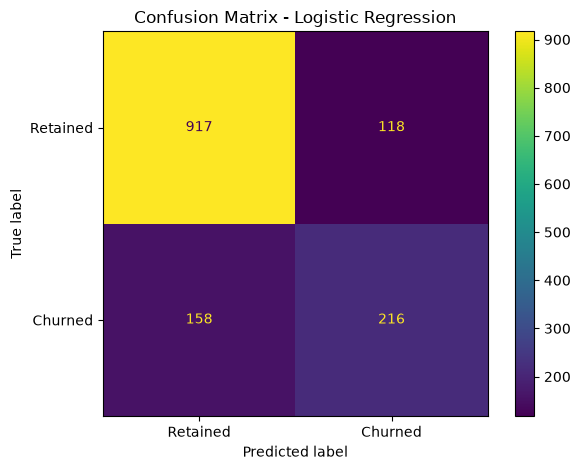

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_lr = lr_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    display_labels=["Retained", "Churned"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

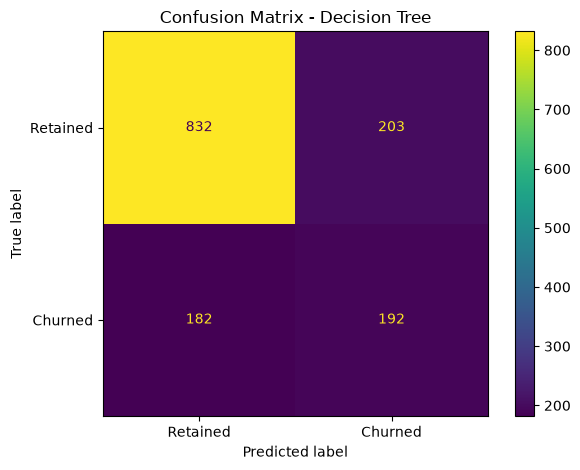

In [15]:
y_pred_dt = dt_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    display_labels=["Retained", "Churned"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix, classification_report

# Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])
tn_lr, fp_lr, fn_lr, tp_lr = cm_lr.ravel()

print("LOGISTIC REGRESSION")
print("Correctly predicted retained customers:", tn_lr)
print("Retained customers incorrectly predicted to churn:", fp_lr)
print("Churners incorrectly predicted to stay:", fn_lr)
print("Correctly identified churners:", tp_lr)
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_lr,
    labels=[0, 1],
    target_names=["Retained", "Churned"],
    zero_division=0
))

# Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()

print("\nDECISION TREE")
print("Correctly predicted retained customers:", tn_dt)
print("Retained customers incorrectly predicted to churn:", fp_dt)
print("Churners incorrectly predicted to stay:", fn_dt)
print("Correctly identified churners:", tp_dt)
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_dt,
    labels=[0, 1],
    target_names=["Retained", "Churned"],
    zero_division=0
))

LOGISTIC REGRESSION
Correctly predicted retained customers: 917
Retained customers incorrectly predicted to churn: 118
Churners incorrectly predicted to stay: 158
Correctly identified churners: 216

Classification Report:
              precision    recall  f1-score   support

    Retained       0.85      0.89      0.87      1035
     Churned       0.65      0.58      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


DECISION TREE
Correctly predicted retained customers: 832
Retained customers incorrectly predicted to churn: 203
Churners incorrectly predicted to stay: 182
Correctly identified churners: 192

Classification Report:
              precision    recall  f1-score   support

    Retained       0.82      0.80      0.81      1035
     Churned       0.49      0.51      0.50       374

    accuracy                           0.73      1409
   macro avg    

## Preliminary Comparison of Original Models

### Confusion Matrix Analysis

The original Logistic Regression and Decision Tree models were evaluated on the same test dataset containing 1,409 customers, of whom 374 had churned.

Logistic Regression correctly identified 216 churners and missed 158. Its churn-class recall was 57.75%, with a precision of 64.67% and an F1-score of 61.02%.

Decision Tree correctly identified 192 churners and missed 182. Its churn-class recall was 51.34%, with a precision of 48.61% and an F1-score of 49.93%.

### Key Findings

1. Logistic Regression identified 24 more churners than Decision Tree.
2. Logistic Regression missed 24 fewer churners.
3. Logistic Regression achieved higher accuracy, precision, recall, and F1-score.
4. Logistic Regression also produced fewer false-positive churn predictions.

### Preliminary Conclusion

Based on the original-model results, Logistic Regression performed better than Decision Tree on this test dataset. It detected a larger proportion of actual churners while producing fewer false positives.

This is a preliminary conclusion. The final recommendation will be made after comparing both original models with their tuned versions.

,Model,Accuracy,Precision,Recall,F1 Score
0,Original Logistic Regression,80.41%,64.67%,57.75%,61.02%
1,Tuned Logistic Regression,79.84%,64.61%,53.21%,58.36%
2,Original Decision Tree,72.96%,49.08%,49.73%,49.40%
3,Tuned Decision Tree,79.35%,63.34%,52.67%,57.52%


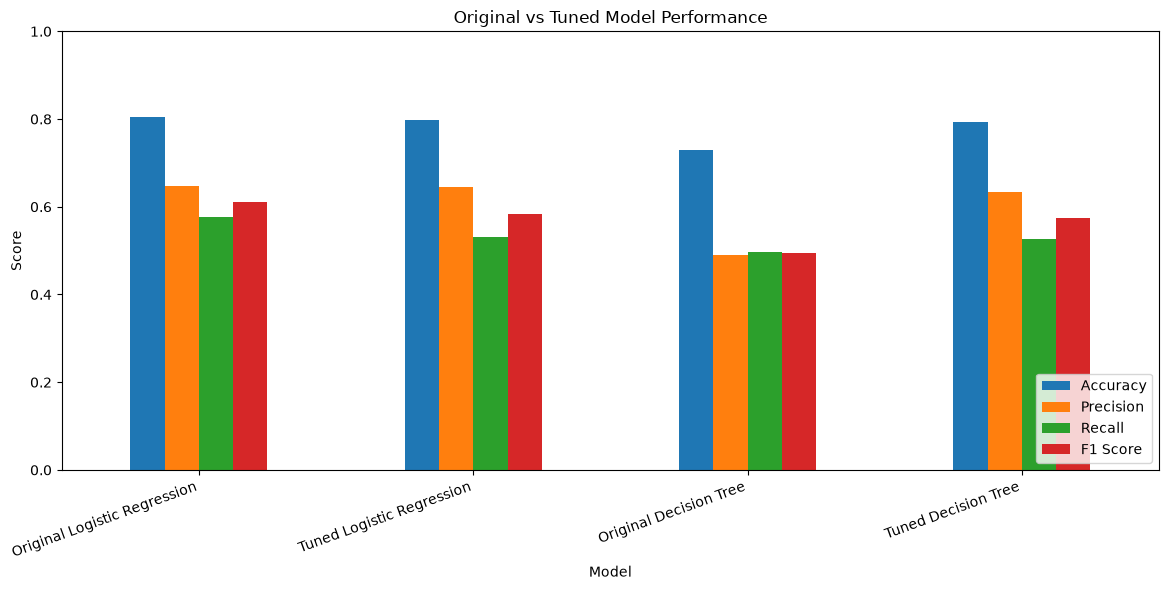

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

# Compare all four models using the results collected
results = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Tuned Logistic Regression",
        "Original Decision Tree",
        "Tuned Decision Tree"
    ],
    "Accuracy": [0.8041, 0.7984, 0.7296, 0.7935],
    "Precision": [0.6467, 0.6461, 0.4908, 0.6334],
    "Recall": [0.5775, 0.5321, 0.4973, 0.5267],
    "F1 Score": [0.6102, 0.5836, 0.4940, 0.5752]
})

# Display comparison table
display(
    results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

# Plot performance comparison
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Original vs Tuned Model Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Final Observations and Conclusion

1. The Original Logistic Regression model achieved the highest test accuracy of **80.41%** and the highest F1-score of **61.02%** among the four reported models.

2. The Tuned Logistic Regression model achieved an accuracy of **79.84%** and an F1-score of **58.36%**. Its reported performance did not improve after tuning.

3. The Original Decision Tree model achieved a test accuracy of **72.96%** and an F1-score of **49.40%**. Its training accuracy was **99.80%**, suggesting possible overfitting.

4. The Tuned Decision Tree model improved its test accuracy to **79.35%** and its F1-score to **57.52%**, showing better reported generalization than the original Decision Tree.

5. The Original Logistic Regression model achieved the highest recall (**57.75%**), making it the strongest of the four models at identifying customers who churned, based on the reported results.

### Conclusion

Based on the reported evaluation metrics, Original Logistic Regression is the preferred model among the four compared models. It achieved the highest test accuracy, recall, and F1-score. Since identifying customers who may leave is important in customer churn prediction, recall and F1-score should be considered alongside accuracy when selecting the final model.

These comparisons assume that the models were evaluated using comparable test data and preprocessing. The Logistic Regression tuning notebook also reported a NaN cross-validation F1-score, so that cross-validation result should not be treated as valid evidence of model performance.